In [2]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
dataset_path = "../dataset"

train_data = pd.read_csv(
    os.path.join(dataset_path, "train_FD001.txt"),
    sep=r"\s+",
    header=None
)

test_data = pd.read_csv(
    os.path.join(dataset_path, "test_FD001.txt"),
    sep=r"\s+",
    header=None
)

rul_data = pd.read_csv(
    os.path.join(dataset_path, "RUL_FD001.txt"),
    sep=r"\s+",
    header=None
)

In [4]:
print("Training data:", train_data.shape)
print("Testing data:", test_data.shape)
print("RUL data:", rul_data.shape)

Training data: (20631, 26)
Testing data: (13096, 26)
RUL data: (100, 1)


In [5]:
display(train_data.head())
display(test_data.head())
display(rul_data.head())

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


,0
0,112
1,98
2,69
3,82
4,91


In [6]:


columns = [
    "engine_id",
    "cycle",
    "setting_1",
    "setting_2",
    "setting_3"
]

# Add 21 sensor column names
sensor_columns = [f"sensor_{i}" for i in range(1, 22)]

# Combine all columns
columns = columns + sensor_columns

# Assign column names
train_data.columns = columns
test_data.columns = columns

# Display column names
print(columns)

# Display first five records
display(train_data.head())

['engine_id', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [7]:
print("Total columns:", len(train_data.columns))
print(train_data.columns.tolist())

Total columns: 26
['engine_id', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']


In [8]:
print("Training engines:", train_data["engine_id"].nunique())
print("Testing engines:", test_data["engine_id"].nunique())

Training engines: 100
Testing engines: 100


In [9]:
print("Minimum cycle:", train_data["cycle"].min())
print("Maximum cycle:", train_data["cycle"].max())

print("\nRecords per engine:")
print(train_data.groupby("engine_id")["cycle"].count().head(10))

Minimum cycle: 1
Maximum cycle: 362

Records per engine:
engine_id
1     192
2     287
3     179
4     189
5     269
6     188
7     259
8     150
9     201
10    222
Name: cycle, dtype: int64


In [10]:
print("Total sensor features:", len(sensor_columns))

display(train_data[sensor_columns].describe().T)

Total sensor features: 21


,count,mean,std,min,25%,50%,75%,max
sensor_1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
sensor_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
sensor_5,20631.0,14.620000,1.776400e-15,14.6200,14.6200,14.6200,14.6200,14.6200
sensor_6,20631.0,21.609803,1.388985e-03,21.6000,21.6100,21.6100,21.6100,21.6100
sensor_7,20631.0,553.367711,8.850923e-01,549.8500,552.8100,553.4400,554.0100,556.0600
sensor_8,20631.0,2388.096652,7.098548e-02,2387.9000,2388.0500,2388.0900,2388.1400,2388.5600
sensor_9,20631.0,9065.242941,2.208288e+01,9021.7300,9053.1000,9060.6600,9069.4200,9244.5900
sensor_10,20631.0,1.300000,0.000000e+00,1.3000,1.3000,1.3000,1.3000,1.3000


In [11]:
# Check missing values
print("Missing values:")
print(train_data.isnull().sum().sum())

# Check duplicate records
print("\nDuplicate records:")
print(train_data.duplicated().sum())

# Check dataset information
print("\nDataset information:")
train_data.info()

Missing values:
0

Duplicate records:


0

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   engine_id  20631 non-null  int64  
 1   cycle      20631 non-null  int64  
 2   setting_1  20631 non-null  float64
 3   setting_2  20631 non-null  float64
 4   setting_3  20631 non-null  float64
 5   sensor_1   20631 non-null  float64
 6   sensor_2   20631 non-null  float64
 7   sensor_3   20631 non-null  float64
 8   sensor_4   20631 non-null  float64
 9   sensor_5   20631 non-null  float64
 10  sensor_6   20631 non-null  float64
 11  sensor_7   20631 non-null  float64
 12  sensor_8   20631 non-null  float64
 13  sensor_9   20631 non-null  float64
 14  sensor_10  20631 non-null  float64
 15  sensor_11  20631 non-null  float64
 16  sensor_12  20631 non-null  float64
 17  sensor_13  20631 non-null  float64
 18  sensor_14  20631 non-null  float64
 19  sensor_15  20631 non-n

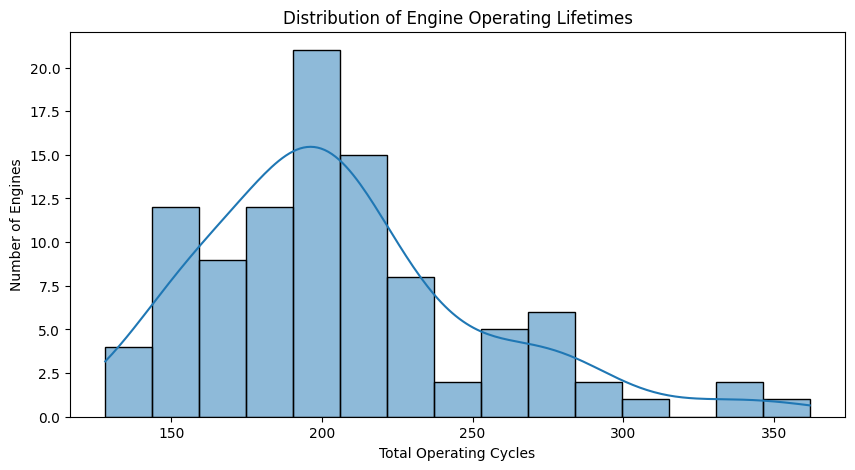

In [12]:
# Calculate maximum cycle for each engine
engine_lifetime = train_data.groupby("engine_id")["cycle"].max()

# Plot distribution
plt.figure(figsize=(10, 5))

sns.histplot(engine_lifetime, bins=15, kde=True)

plt.title("Distribution of Engine Operating Lifetimes")
plt.xlabel("Total Operating Cycles")
plt.ylabel("Number of Engines")

plt.show()

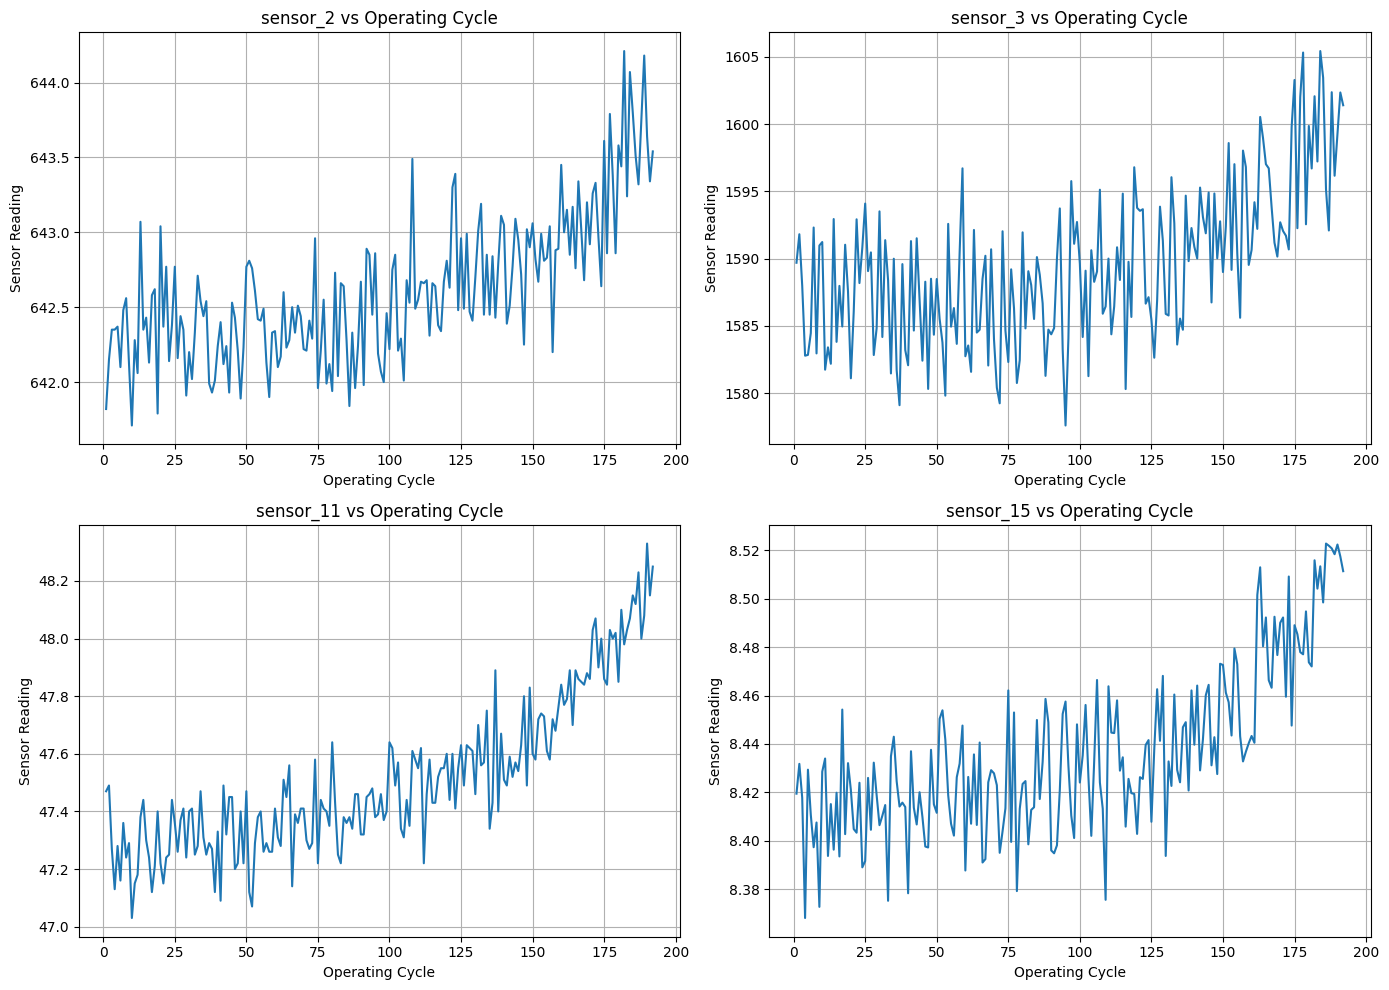

In [13]:
# Select one engine
engine_1 = train_data[train_data["engine_id"] == 1]

# Select sensors
selected_sensors = [
    "sensor_2",
    "sensor_3",
    "sensor_11",
    "sensor_15"
]

# Plot sensor trends
plt.figure(figsize=(14, 10))

for i, sensor in enumerate(selected_sensors, 1):

    plt.subplot(2, 2, i)

    plt.plot(
        engine_1["cycle"],
        engine_1[sensor]
    )

    plt.title(f"{sensor} vs Operating Cycle")
    plt.xlabel("Operating Cycle")
    plt.ylabel("Sensor Reading")
    plt.grid(True)

plt.tight_layout()
plt.show()

In [14]:
# Calculate variance of all sensor features
sensor_variance = train_data[sensor_columns].var()

# Display variance
print("Sensor Variance:")
display(sensor_variance.sort_values())

# Identify near-constant sensors
low_variance_sensors = sensor_variance[
    sensor_variance < 1e-8
].index.tolist()

print("\nNear-constant sensors:")
print(low_variance_sensors)

print("\nNumber of sensors to remove:", len(low_variance_sensors))

Sensor Variance:


sensor_1     0.000000e+00
sensor_10    0.000000e+00
sensor_19    0.000000e+00
sensor_18    0.000000e+00
sensor_16    1.926023e-34
sensor_5     3.155597e-30
sensor_6     1.929279e-06
sensor_15    1.406628e-03
sensor_8     5.038938e-03
sensor_13    5.172330e-03
sensor_21    1.171825e-02
sensor_20    3.266927e-02
sensor_11    7.133568e-02
sensor_2     2.500533e-01
sensor_12    5.439850e-01
sensor_7     7.833883e-01
sensor_17    2.398667e+00
sensor_3     3.759099e+01
sensor_4     8.101089e+01
sensor_14    3.639005e+02
sensor_9     4.876536e+02
dtype: float64


Near-constant sensors:
['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']

Number of sensors to remove: 6


In [15]:
# Identify useful sensors
selected_sensors = [
    sensor for sensor in sensor_columns
    if sensor not in low_variance_sensors
]

print("Original sensor count:", len(sensor_columns))

print("Sensors removed:", len(low_variance_sensors))

print("Remaining sensor count:", len(selected_sensors))

print("\nSelected sensors:")
print(selected_sensors)

Original sensor count: 21
Sensors removed: 6
Remaining sensor count: 15

Selected sensors:
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [16]:
test_variance = test_data[sensor_columns].var()

print("Testing variance of removed sensors:")

display(test_variance[low_variance_sensors])

Testing variance of removed sensors:


sensor_1     0.000000e+00
sensor_5     3.155685e-30
sensor_10    4.930757e-32
sensor_16    1.083418e-34
sensor_18    0.000000e+00
sensor_19    0.000000e+00
dtype: float64

In [17]:
selected_sensors = [
    'sensor_2',
    'sensor_3',
    'sensor_4',
    'sensor_6',
    'sensor_7',
    'sensor_8',
    'sensor_9',
    'sensor_11',
    'sensor_12',
    'sensor_13',
    'sensor_14',
    'sensor_15',
    'sensor_17',
    'sensor_20',
    'sensor_21'
]

# Find maximum operating cycle for each engine

max_cycle = train_data.groupby("engine_id")["cycle"].max()

print(max_cycle.head(10))

engine_id
1     192
2     287
3     179
4     189
5     269
6     188
7     259
8     150
9     201
10    222
Name: cycle, dtype: int64


In [19]:
# Calculate actual RUL

train_data["RUL"] = (
    train_data.groupby("engine_id")["cycle"].transform("max")
    - train_data["cycle"]
)

# Display records
display(train_data[["engine_id", "cycle", "RUL"]].head(10))

display(
    train_data[train_data["engine_id"] == 1][
        ["engine_id", "cycle", "RUL"]
    ].tail(10)
)

,engine_id,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187
5,1,6,186
6,1,7,185
7,1,8,184
8,1,9,183
9,1,10,182


,engine_id,cycle,RUL
182,1,183,9
183,1,184,8
184,1,185,7
185,1,186,6
186,1,187,5
187,1,188,4
188,1,189,3
189,1,190,2
190,1,191,1
191,1,192,0


In [20]:
print("RUL Statistical Summary:")
print(train_data["RUL"].describe())

RUL Statistical Summary:
count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: RUL, dtype: float64


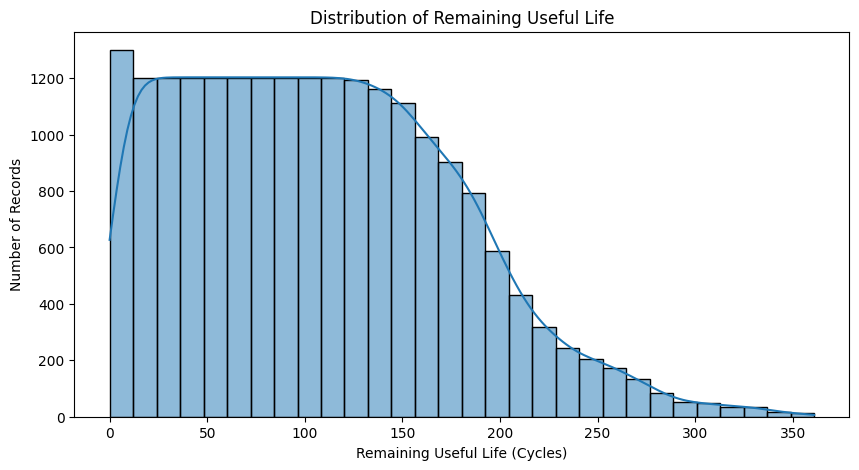

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    data=train_data,
    x="RUL",
    bins=30,
    kde=True
)

plt.title("Distribution of Remaining Useful Life")
plt.xlabel("Remaining Useful Life (Cycles)")
plt.ylabel("Number of Records")

plt.show()

In [22]:
above_125 = (train_data["RUL"] > 125).sum()

print("Records with RUL above 125:", above_125)
print("Total training records:", len(train_data))
print("Percentage above 125:", round(
    above_125 / len(train_data) * 100, 2
), "%")

Records with RUL above 125: 8031
Total training records: 20631
Percentage above 125: 38.93 %


In [24]:
# Preserve original RUL values
train_data["RUL_raw"] = train_data["RUL"]

# Create capped RUL
train_data["RUL_capped"] = train_data["RUL"].clip(upper=125)

# Check the results
print(train_data[["RUL", "RUL_capped"]].describe())


print(
    "Records capped:",
    (train_data["RUL"] > 125).sum()
)

print(
    "Maximum capped RUL:",
    train_data["RUL_capped"].max()
)

                RUL    RUL_capped
count  20631.000000  20631.000000
mean     107.807862     86.829286
std       68.880990     41.673699
min        0.000000      0.000000
25%       51.000000     51.000000
50%      103.000000    103.000000
75%      155.000000    125.000000
max      361.000000    125.000000
Records capped: 8031
Maximum capped RUL: 125


In [25]:
print("Testing data shape:", test_data.shape)
print("RUL file shape:", rul_data.shape)

print("\nFirst 5 RUL values:")
print(rul_data.head())

Testing data shape: (13096, 26)
RUL file shape: (100, 1)

First 5 RUL values:
     0
0  112
1   98
2   69
3   82
4   91


In [26]:
# Get unique test engine IDs
test_engine_ids = sorted(test_data["engine_id"].unique())

# Map NASA RUL values to engine IDs
rul_mapping = dict(zip(
    test_engine_ids,
    rul_data[0].values
))

print("First 5 RUL mappings:")
print(dict(list(rul_mapping.items())[:5]))

First 5 RUL mappings:
{np.int64(1): np.int64(112), np.int64(2): np.int64(98), np.int64(3): np.int64(69), np.int64(4): np.int64(82), np.int64(5): np.int64(91)}


In [27]:
# Find the final recorded cycle of each test engine
test_max_cycle = test_data.groupby("engine_id")["cycle"].transform("max")

# Calculate raw RUL
test_data["RUL_raw"] = (
    test_data["engine_id"].map(rul_mapping)
    + test_max_cycle
    - test_data["cycle"]
)

# Apply 125-cycle cap
test_data["RUL_capped"] = test_data["RUL_raw"].clip(upper=125)

# Display first 10 records
display(
    test_data[
        ["engine_id", "cycle", "RUL_raw", "RUL_capped"]
    ].head(10)
)

,engine_id,cycle,RUL_raw,RUL_capped
0,1,1,142,125
1,1,2,141,125
2,1,3,140,125
3,1,4,139,125
4,1,5,138,125
5,1,6,137,125
6,1,7,136,125
7,1,8,135,125
8,1,9,134,125
9,1,10,133,125


In [28]:
print("Missing RUL values:", test_data["RUL_raw"].isnull().sum())

print("\nRaw RUL statistics:")
print(test_data["RUL_raw"].describe())

print("\nCapped RUL statistics:")
print(test_data["RUL_capped"].describe())

Missing RUL values: 0

Raw RUL statistics:
count    13096.000000
mean       141.238470
std         58.980114
min          7.000000
25%        102.000000
50%        140.000000
75%        179.000000
max        340.000000
Name: RUL_raw, dtype: float64

Capped RUL statistics:
count    13096.000000
mean       108.919823
std         27.580258
min          7.000000
25%        102.000000
50%        125.000000
75%        125.000000
max        125.000000
Name: RUL_capped, dtype: float64


In [30]:
test_last_rows = test_data.groupby("engine_id").tail(1)

display(
    test_last_rows[
        ["engine_id", "cycle", "RUL_raw", "RUL_capped"]
    ].head()
)

,engine_id,cycle,RUL_raw,RUL_capped
30,1,31,112,112
79,2,49,98,98
205,3,126,69,69
311,4,106,82,82
409,5,98,91,91


In [31]:
operating_settings = [
    "setting_1",
    "setting_2",
    "setting_3"
]

selected_sensors = [
    "sensor_2", "sensor_3", "sensor_4",
    "sensor_6", "sensor_7", "sensor_8",
    "sensor_9", "sensor_11", "sensor_12",
    "sensor_13", "sensor_14", "sensor_15",
    "sensor_17", "sensor_20", "sensor_21"
]

feature_columns = operating_settings + selected_sensors

print("Total features:", len(feature_columns))

Total features: 18


In [32]:
X_train = train_data[feature_columns]
y_train = train_data["RUL_capped"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

X_train: (20631, 18)
y_train: (20631,)


In [33]:
X_test = test_data[feature_columns]
y_test = test_data["RUL_capped"]

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_test: (13096, 18)
y_test: (13096,)


In [34]:
print("Training features:")
display(X_train.head())

print("Training target:")
display(y_train.head())

print("Testing features:")
display(X_test.head())

print("Testing target:")
display(y_test.head())


Training features:


,setting_1,setting_2,setting_3,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
0,-0.0007,-0.0004,100.0,641.82,1589.70,1400.60,21.61,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190
1,0.0019,-0.0003,100.0,642.15,1591.82,1403.14,21.61,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236
2,-0.0043,0.0003,100.0,642.35,1587.99,1404.20,21.61,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442
3,0.0007,0.0000,100.0,642.35,1582.79,1401.87,21.61,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739
4,-0.0019,-0.0002,100.0,642.37,1582.85,1406.22,21.61,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044


Training target:


0    125
1    125
2    125
3    125
4    125
Name: RUL_capped, dtype: int64

Testing features:


,setting_1,setting_2,setting_3,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
0,0.0023,0.0003,100.0,643.02,1585.29,1398.21,21.61,553.90,2388.04,9050.17,47.20,521.72,2388.03,8125.55,8.4052,392,38.86,23.3735
1,-0.0027,-0.0003,100.0,641.71,1588.45,1395.42,21.61,554.85,2388.01,9054.42,47.50,522.16,2388.06,8139.62,8.3803,393,39.02,23.3916
2,0.0003,0.0001,100.0,642.46,1586.94,1401.34,21.61,554.11,2388.05,9056.96,47.50,521.97,2388.03,8130.10,8.4441,393,39.08,23.4166
3,0.0042,0.0000,100.0,642.44,1584.12,1406.42,21.61,554.07,2388.03,9045.29,47.28,521.38,2388.05,8132.90,8.3917,391,39.00,23.3737
4,0.0014,0.0000,100.0,642.51,1587.19,1401.92,21.61,554.16,2388.01,9044.55,47.31,522.15,2388.03,8129.54,8.4031,390,38.99,23.4130


Testing target:


0    125
1    125
2    125
3    125
4    125
Name: RUL_capped, dtype: int64

In [35]:
import os

os.makedirs("../processed", exist_ok=True)

X_train.to_csv("../processed/X_train.csv", index=False)
y_train.to_csv("../processed/y_train.csv", index=False)

X_test.to_csv("../processed/X_test.csv", index=False)
y_test.to_csv("../processed/y_test.csv", index=False)

In [36]:
import joblib

joblib.dump(feature_columns, "../processed/feature_columns.pkl")

['../processed/feature_columns.pkl']

In [37]:
train_data[["engine_id"]].to_csv(
    "../processed/train_engine_ids.csv",
    index=False
)